In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_colwidth', None)

In [2]:
data1 = pd.read_csv('train.csv')
data2 = pd.read_csv('test.csv')

train_df = data1.copy()
test_df = data2.copy()

print("First 5 rows train data: \n", train_df.head())
print()
print("First 5 rows test data: \n", test_df.head())

First 5 rows train data: 
    id  Age  Flight Distance  Inflight wifi service  \
0   0   36              694                      4   
1   1   56              651                      5   
2   2   31             1371                      3   
3   3   10             1616                      3   
4   4   23              481                      3   

   Departure/Arrival time convenient  Ease of Online booking  Gate location  \
0                                  4                       4              3   
1                                  5                       5              5   
2                                  4                       2              5   
3                                  5                       3              3   
4                                  4                       3              4   

   Food and drink  Online boarding  Seat comfort  ...  Baggage handling  \
0               1                4             1  ...                 4   
1               5      

In [3]:
map_enc_cols_train = [
    'satisfaction'
]

dummy_cols = [
    'Gender',
    'Customer Type',
    'Type of Travel',
    'Class'
]

for col in map_enc_cols_train:
    train_df[col] = train_df[col].astype(int)

for col in dummy_cols:
    dummies_train = pd.get_dummies(train_df[col], prefix=col, dtype=int)
    dummies_test = pd.get_dummies(test_df[col], prefix=col, dtype=int)

    dummies_test = dummies_test.reindex(columns=dummies_train.columns, fill_value=0)

    train_df = pd.concat([train_df, dummies_train], axis=1)
    test_df = pd.concat([test_df, dummies_test], axis=1)

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

target = 'satisfaction'
drop_cols = ['id', target] + dummy_cols

X = train_df.drop(columns=drop_cols)
y = train_df[target]
X_test = test_df.drop(columns=['id'] + dummy_cols)[X.columns]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_val.shape, X_test.shape)

(559708, 26) (139927, 26) (299844, 26)


In [5]:
model = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    early_stopping_rounds=50,
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=100
)

val_pred = model.predict_proba(X_val)[:, 1]
print("Val ROC AUC:", roc_auc_score(y_val, val_pred))
print("Best iteration:", model.best_iteration)

[0]	validation_0-auc:0.94309
[100]	validation_0-auc:0.95482
[200]	validation_0-auc:0.95641
[300]	validation_0-auc:0.95700
[400]	validation_0-auc:0.95728
[500]	validation_0-auc:0.95748
[600]	validation_0-auc:0.95759
[700]	validation_0-auc:0.95765
[800]	validation_0-auc:0.95770
[862]	validation_0-auc:0.95770
Val ROC AUC: 0.9577153332072336
Best iteration: 812


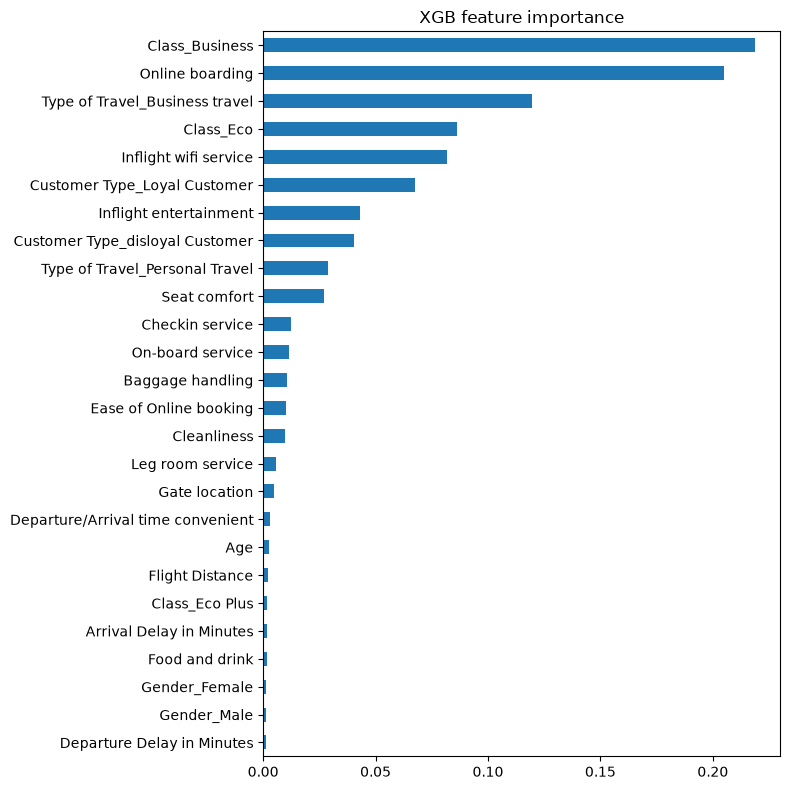

In [6]:
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values()
importances.plot(kind='barh', figsize=(8, 8))
plt.title('XGB feature importance')
plt.tight_layout()
plt.show()

Validation ROC AUC Score: 0.9577


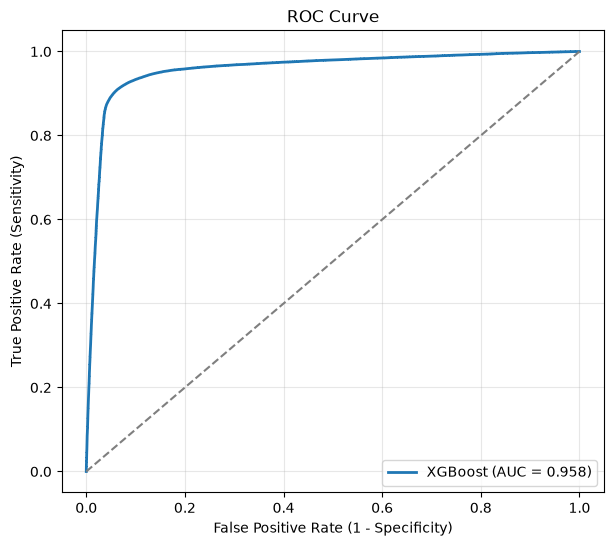

In [7]:
from sklearn.metrics import roc_auc_score, roc_curve

y_val_probs = model.predict_proba(X_val)[:, 1]

auc_score = roc_auc_score(y_val, y_val_probs)
print(f"Validation ROC AUC Score: {auc_score:.4f}")

fpr, tpr, thresholds = roc_curve(y_val, y_val_probs)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='tab:blue', lw=2, label=f'XGBoost (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], color='tab:gray', linestyle='--')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

In [8]:
import optuna
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

def objective(trial):
    params = {
        'n_estimators': 2000,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 20),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'gamma': trial.suggest_float('gamma', 1e-8, 5.0, log=True),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'early_stopping_rounds': 50,
        'tree_method': 'hist',
        'random_state': 42,
        'n_jobs': -1
    }
    m = XGBClassifier(**params)
    m.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    trial.set_user_attr('best_iteration', m.best_iteration)
    return roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])

study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42),
    pruner=optuna.pruners.MedianPruner()
)
study.optimize(objective, n_trials=50, show_progress_bar=True)

print("Best AUC:", study.best_value)
print("Best params:", study.best_params)
print("Best iteration:", study.best_trial.user_attrs['best_iteration'])

[I 2026-10-02 22:40:58,008] A new study created in memory with name: no-name-3a3c8812-5804-43ca-bbbb-db59749acdd9
Best trial: 0. Best value: 0.958158:   2%|▏         | 1/50 [00:48<39:24, 48.25s/it]

[I 2026-10-02 22:41:46,252] Trial 0 finished with value: 0.9581584271082293 and parameters: {'learning_rate': 0.030710573677773714, 'max_depth': 10, 'min_child_weight': 15, 'subsample': 0.7993292420985183, 'colsample_bytree': 0.5780093202212182, 'gamma': 2.275053705838343e-07, 'reg_alpha': 3.3323645788192616e-08, 'reg_lambda': 0.6245760287469893}. Best is trial 0 with value: 0.9581584271082293.


Best trial: 0. Best value: 0.958158:   4%|▍         | 2/50 [01:20<31:08, 38.92s/it]

[I 2026-10-02 22:42:18,650] Trial 1 finished with value: 0.957765954799954 and parameters: {'learning_rate': 0.06054365855469246, 'max_depth': 8, 'min_child_weight': 1, 'subsample': 0.9849549260809971, 'colsample_bytree': 0.9162213204002109, 'gamma': 7.032853236588588e-07, 'reg_alpha': 4.329370014459266e-07, 'reg_lambda': 4.4734294104626844e-07}. Best is trial 0 with value: 0.9581584271082293.


Best trial: 0. Best value: 0.958158:   6%|▌         | 3/50 [02:55<50:25, 64.37s/it]

...

[I 2026-10-03 00:07:56,180] Trial 47 finished with value: 0.9581723641531402 and parameters: {'learning_rate': 0.015238254806994539, 'max_depth': 10, 'min_child_weight': 19, 'subsample': 0.8784934252166757, 'colsample_bytree': 0.6379272347116886, 'gamma': 1.2307653194281185e-08, 'reg_alpha': 0.005340721020953497, 'reg_lambda': 0.00038348650979601887}. Best is trial 15 with value: 0.9582608357233477.


Best trial: 15. Best value: 0.958261:  98%|█████████▊| 49/50 [1:28:39<01:48, 108.10s/it]

[I 2026-10-03 00:09:37,016] Trial 48 finished with value: 0.958163543452118 and parameters: {'learning_rate': 0.013619776682352586, 'max_depth': 10, 'min_child_weight': 16, 'subsample': 0.8446194384113482, 'colsample_bytree': 0.6300708368963118, 'gamma': 1.0624184204718695e-08, 'reg_alpha': 7.97954859154315e-06, 'reg_lambda': 4.3546378585684164e-05}. Best is trial 15 with value: 0.9582608357233477.


Best trial: 15. Best value: 0.958261: 100%|██████████| 50/50 [1:30:47<00:00, 108.94s/it]

[I 2026-10-03 00:11:45,087] Trial 49 finished with value: 0.9582117323759302 and parameters: {'learning_rate': 0.011153707173182899, 'max_depth': 10, 'min_child_weight': 18, 'subsample': 0.9412478728195443, 'colsample_bytree': 0.6272711888792716, 'gamma': 1.6839601259103225e-08, 'reg_alpha': 0.028248804502635748, 'reg_lambda': 0.008447244953176626}. Best is trial 15 with value: 0.9582608357233477.
Best AUC: 0.9582608357233477
Best params: {'learning_rate': 0.010346185540963155, 'max_depth': 10, 'min_child_weight': 16, 'subsample': 0.8688218919542033, 'colsample_bytree': 0.5904418282366768, 'gamma': 1.9292026506893206e-08, 'reg_alpha': 0.00021509775607303047, 'reg_lambda': 4.599723522365536e-05}
Best iteration: 1426


In [9]:
import json

with open('best_xgb_base_params.json', 'w') as f:
    json.dump(study.best_params, f, indent=4)

print("best_xgb_base_params.json")

best_xgb_base_params.json


In [10]:
with open("best_xgb_base_params.json") as f:
    best_xgb_base_params = json.load(f)

print("Frozen LogReg params:")
for k, v in best_xgb_base_params.items():
    print(f"  {k}: {v}")

Frozen LogReg params:
  learning_rate: 0.010346185540963155
  max_depth: 10
  min_child_weight: 16
  subsample: 0.8688218919542033
  colsample_bytree: 0.5904418282366768
  gamma: 1.9292026506893206e-08
  reg_alpha: 0.00021509775607303047
  reg_lambda: 4.599723522365536e-05


In [12]:
best_model = XGBClassifier(
    **study.best_params,
    n_estimators=study.best_trial.user_attrs['best_iteration'] + 1,
    objective='binary:logistic',
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)
best_model.fit(X, y)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.5904418282366768
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [13]:
test_pred = model.predict_proba(X_test)[:, 1]

submission = pd.DataFrame({'id': test_df['id'], 'satisfaction': test_pred})
submission.to_csv('submission_xgb_base2.csv', index=False)
print("Success!")

Success!
